# ANÁLISE DE VENDAS - SUPERMERCADO 
**Objetivo:** Identificar padrões de vendas e oportunidades de melhorias

**Dados:** 1.000 transações de 3 filiais (Janeiro a Março de 2019)

**Ferramentas:** Python, Pandas, Seaborn, Matplotlib


In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

# Formatando para moeda brasileira
pd.options.display.float_format = '{:,.2f}'.format

tabela = pd.read_csv('SuperMarket Analysis.csv')

#Substituir Valores : 

tabela = tabela.rename(columns={
    'Invoice ID'              : 'id_fatura',
    'Branch'                  : 'filial',
    'City'                    : 'cidade',
    'Customer type'           : 'tipo_cliente',
    'Gender'                  : 'genero',
    'Product line'            : 'categoria',
    'Unit price'              : 'preco_unitario',
    'Quantity'                : 'quantidade',
    'Tax 5%'                  : 'imposto',
    'Sales'                   : 'vendas',
    'Date'                    : 'data',
    'Time'                    : 'horario',
    'Payment'                 : 'pagamento',
    'cogs'                    : 'custo',
    'gross margin percentage' : 'margem_percentual',
    'gross income'            : 'lucro_bruto',
    'Rating'                  : 'avaliacao'
})

tabela['pagamento'] = tabela['pagamento'].replace({
    'Cash'        : 'Dinheiro',
    'Credit card' : 'Cartão de crédito',
    'Ewallet'     : 'Pix'
})

tabela['genero'] = tabela['genero'].replace({
    'Female' : 'Feminino',
    'Male'   : 'Masculino'
})

tabela['categoria'] = tabela['categoria'].replace({
    'Fashion accessories'    : 'Acessórios de moda',
    'Food and beverages'     : 'Alimentos e bebidas',
    'Electronic accessories' : 'Acessórios eletrônicos',
    'Sports and travel'      : 'Esportes e viagem',
    'Home and lifestyle'     : 'Casa e estilo de vida',
    'Health and beauty'      : 'Saúde e beleza'
})



tabela['data']    = pd.to_datetime(tabela['data'])
tabela['horario'] = pd.to_datetime(tabela['horario'], errors='coerce')

tabela['mes']        = tabela['data'].dt.month
tabela['dia_semana'] = tabela['data'].dt.dayofweek
tabela['hora']       = tabela['horario'].dt.hour

# Selecionar Colunas : 

tabela = tabela[['filial', 'cidade', 'tipo_cliente', 'genero', 'categoria',
                  'preco_unitario', 'quantidade', 'vendas', 'pagamento',
                  'avaliacao', 'lucro_bruto', 'mes', 'dia_semana', 'hora',]]

# 6. Renomear valores de mês e dia_semana : 

tabela['mes'] = tabela['mes'].replace({
    1 : 'Janeiro',
    2 : 'Fevereiro',
    3 : 'Março'
})

tabela['dia_semana'] = tabela['dia_semana'].replace({
    0 : 'Segunda-feira',
    1 : 'Terça-feira',
    2 : 'Quarta-feira',
    3 : 'Quinta-feira',
    4 : 'Sexta-feira',
    5 : 'Sábado',
    6 : 'Domingo'
})



display(tabela.dtypes)
display(tabela.isnull().sum())
display(tabela.describe())
tabela.head()  

C:\Users\Samsung\AppData\Local\Temp\ipykernel_9520\1329209812.py:55: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  tabela['horario'] = pd.to_datetime(tabela['horario'], errors='coerce')


filial                str
cidade                str
tipo_cliente          str
genero                str
categoria             str
preco_unitario    float64
quantidade          int64
vendas            float64
pagamento             str
avaliacao         float64
lucro_bruto       float64
mes                object
dia_semana         object
hora                int32
dtype: object

filial            0
cidade            0
tipo_cliente      0
genero            0
categoria         0
preco_unitario    0
quantidade        0
vendas            0
pagamento         0
avaliacao         0
lucro_bruto       0
mes               0
dia_semana        0
hora              0
dtype: int64

,preco_unitario,quantidade,vendas,avaliacao,lucro_bruto,hora
count,"1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00"
mean,55.67,5.51,322.97,6.97,15.38,14.91
std,26.49,2.92,245.89,1.72,11.71,3.19
min,10.08,1.00,10.68,4.00,0.51,10.00
25%,32.88,3.00,124.42,5.50,5.92,12.00
50%,55.23,5.00,253.85,7.00,12.09,15.00
75%,77.94,8.00,471.35,8.50,22.45,18.00
max,99.96,10.00,"1,042.65",10.00,49.65,20.00


,filial,cidade,tipo_cliente,genero,categoria,preco_unitario,quantidade,vendas,pagamento,avaliacao,lucro_bruto,mes,dia_semana,hora
0,Alex,Yangon,Member,Feminino,Saúde e beleza,74.69,7,548.97,Pix,9.10,26.14,Janeiro,Sábado,13
1,Giza,Naypyitaw,Normal,Feminino,Acessórios eletrônicos,15.28,5,80.22,Dinheiro,9.60,3.82,Março,Sexta-feira,10
2,Alex,Yangon,Normal,Feminino,Casa e estilo de vida,46.33,7,340.53,Cartão de crédito,7.40,16.22,Março,Domingo,13
3,Alex,Yangon,Member,Feminino,Saúde e beleza,58.22,8,489.05,Pix,8.40,23.29,Janeiro,Domingo,20
4,Alex,Yangon,Member,Feminino,Esportes e viagem,86.31,7,634.38,Pix,5.30,30.21,Fevereiro,Sexta-feira,10


In [2]:
# Cores disponíveis
verde  = '\033[92m'
verdeclaro = "98FB98"
amarelo = '\033[93m'
vermelho = '\033[91m'
azul= '\033[94m'
reset = '\033[0m'
negrito  = '\033[1m'
roxo  = '\033[95m'
ciano   = '\033[96m'
laranja  = '\033[33m'

Qual filial vende mais ?



filial
Alex     340
Cairo    332
Giza     328
Name: vendas, dtype: int64

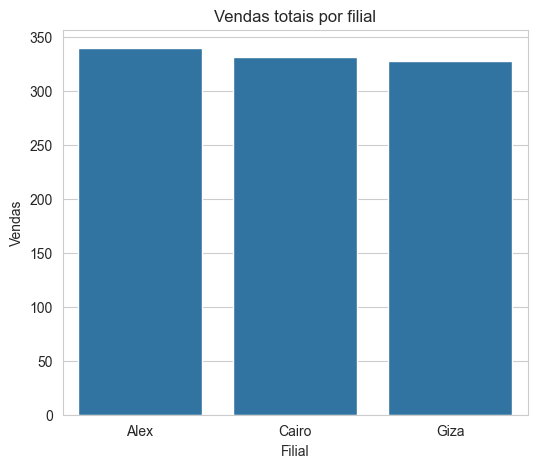

Qual filial gera mais receita


filial
Giza    110,568.71
Alex    106,200.37
Cairo   106,197.67
Name: vendas, dtype: float64

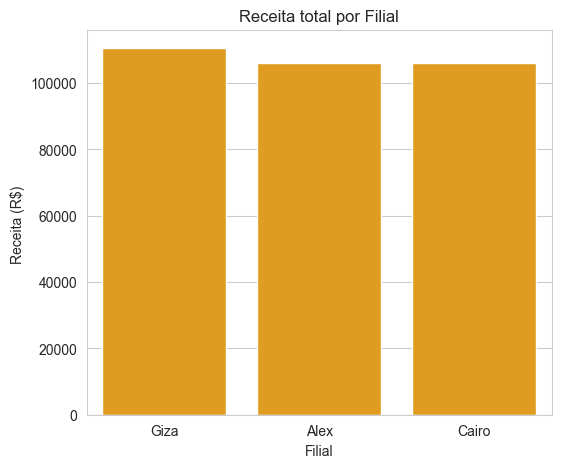

Ticket Médio:


filial
Giza    337.10
Cairo   319.87
Alex    312.35
Name: vendas, dtype: float64

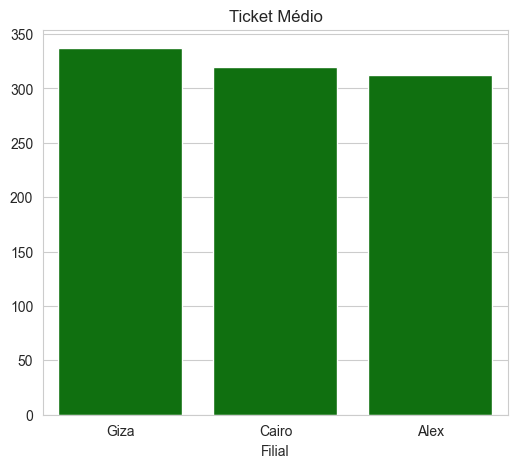

In [3]:
# MAO NA MASSA  : 
# Qual filial Vende mais? : 

print( "Qual filial vende mais ?\n")
display(tabela.groupby("filial")["vendas"].count().sort_values(ascending= False))

# Criação Dos  Gráficos : 

sns.set_style("whitegrid")

vendas_filial= tabela.groupby("filial")["vendas"].count().sort_values(ascending= False)

plt.figure(figsize=(6,5))

sns.set_style("whitegrid")

sns.barplot(
    
x = vendas_filial.index,
y = vendas_filial.values,

)

plt.title("Vendas totais por filial")
plt.xlabel("Filial")
plt.ylabel("Vendas")
plt.show()

# Qual filial gera mais receita ?  : 

print("Qual filial gera mais receita") 
display(tabela.groupby("filial")["vendas"].sum().sort_values(ascending = False))

receita_filial = tabela.groupby("filial")["vendas"].sum().sort_values(ascending = False)

sns.set_style("whitegrid")

plt.figure(figsize = (6,5))

sns.barplot(
    x = receita_filial.index , 

    y = receita_filial.values, 

    color = "orange"
)


plt.title("Receita total por Filial")
plt.xlabel("Filial")
plt.ylabel("Receita (R$) ")
plt.show()



# Ticket Médio : 

print("Ticket Médio:") 
display(tabela.groupby("filial")["vendas"].mean().round(2).sort_values(ascending= False))

ticket_médio = tabela.groupby("filial")["vendas"].mean().round(2).sort_values(ascending= False)

plt.figure(figsize= (6,5))


sns.set_style("whitegrid")

sns.barplot(
  x = ticket_médio.index , 
  y = ticket_médio.values , 
  color = "green" , 
)
plt.title("Ticket Médio")
plt.xlabel("Filial")
plt.show()


Qual forma de pagamento e mais usada ? 


pagamento
Pix                  345
Dinheiro             344
Cartão de crédito    311
Name: count, dtype: int64

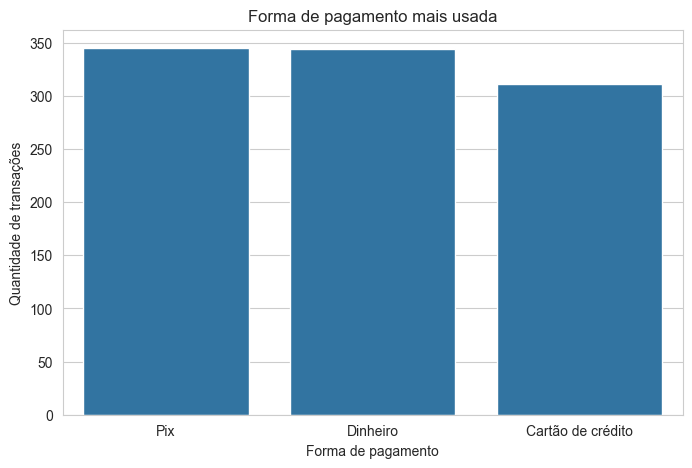

Qual gera mais receita ? 


pagamento
Dinheiro            112,206.57
Pix                 109,993.11
Cartão de crédito   100,767.07
Name: vendas, dtype: float64

In [4]:
print("Qual forma de pagamento e mais usada ? ")

display(tabela["pagamento"].value_counts())

plt.figure(figsize=(8,5))

sns.countplot(
    data = tabela,
    x = 'pagamento',
    order = tabela['pagamento'].value_counts().index
)

plt.title('Forma de pagamento mais usada')
plt.xlabel('Forma de pagamento')
plt.ylabel('Quantidade de transações')
plt.show()


print("Qual gera mais receita ? ")
display(tabela.groupby("pagamento")["vendas"].sum().sort_values(ascending=False))


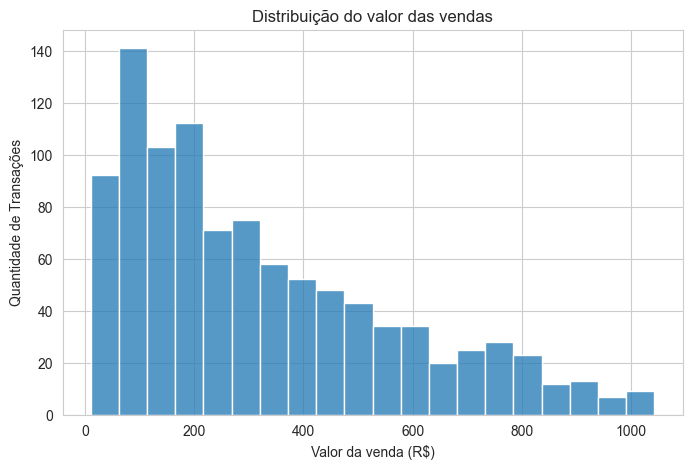

 Entre R$50 até R$300 Reais, Compras acima de R$600 Reais são raras.


In [5]:
# qual é o perfil de gasto típico do cliente?

plt.figure(figsize=(8,5))

sns.histplot(data=tabela, x='vendas', bins=20)

plt.title('Distribuição do valor das vendas')
plt.xlabel('Valor da venda (R$)')
plt.ylabel("Quantidade de Transações")
plt.show()

print(f"{verde}{negrito} Entre R$50 até R$300 Reais, Compras acima de R$600 Reais são raras.{reset}")


In [6]:
# Clientes members Vs Normal : 
print("Cliente members Vs Normal")

display(tabela.groupby("tipo_cliente")["vendas"].mean().sort_values(ascending = False).round(2))

Cliente members Vs Normal


tipo_cliente
Member   335.74
Normal   306.37
Name: vendas, dtype: float64

In [7]:
# Qual horário tem mais movimento nos supermercados ? :
print("Qual horário tem mais movimento nos supermercados ?")

# Filial Alex

print(f"{negrito}{roxo}Horário de pico - Alex{reset}")
alex = tabela[tabela["filial"] == "Alex"]
resultado_alex = alex.groupby("hora")["vendas"].sum().sort_values(ascending = False).head(3)

resultado_alex.index = resultado_alex.index.astype(str) + "h"

display(resultado_alex)

# Filial Giza 

print(f"{negrito}{roxo}Hórario de pico - Giza{reset}")

giza = tabela[tabela["filial"] == "Giza"]

resultado_giza = giza.groupby("hora")["vendas"].sum().sort_values(ascending = False).head(3)

resultado_giza.index = resultado_giza.index.astype(str) + "h"

display(resultado_giza)

# Filial Cairo
print(f"{negrito}{roxo}Horário de pico - Cairo{reset}")
cairo = tabela[tabela["filial"] == "Cairo"]

resultado_cairo = cairo.groupby("hora")["vendas"].sum().sort_values(ascending = False).head(3)

resultado_cairo.index = resultado_cairo.index.astype("str") + "h"

display(resultado_cairo)

Qual horário tem mais movimento nos supermercados ?
Horário de pico - Alex


hora
11h   11,349.89
15h   11,273.70
10h   11,208.41
Name: vendas, dtype: float64

Hórario de pico - Giza


hora
19h   13,106.80
13h   13,007.06
10h   11,347.22
Name: vendas, dtype: float64

Horário de pico - Cairo


hora
19h   16,262.45
14h   11,694.56
13h   11,272.41
Name: vendas, dtype: float64

Qual  categoria gera mais receita ? 


categoria
Alimentos e bebidas      56,144.84
Esportes e viagem        55,122.83
Acessórios eletrônicos   54,337.53
Acessórios de moda       54,305.89
Casa e estilo de vida    53,861.91
Saúde e beleza           49,193.74
Name: vendas, dtype: float64

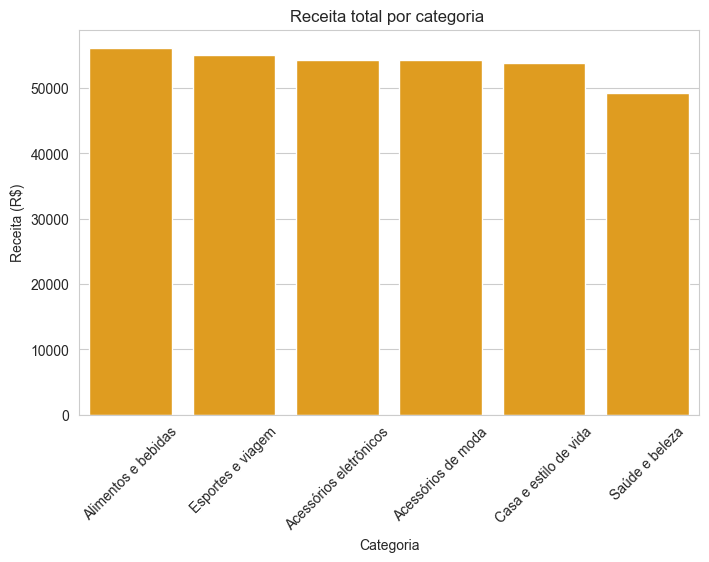

Qual categoria tem mais vendas ? 


categoria
Acessórios de moda        178
Alimentos e bebidas       174
Acessórios eletrônicos    170
Esportes e viagem         166
Casa e estilo de vida     160
Saúde e beleza            152
Name: count, dtype: int64

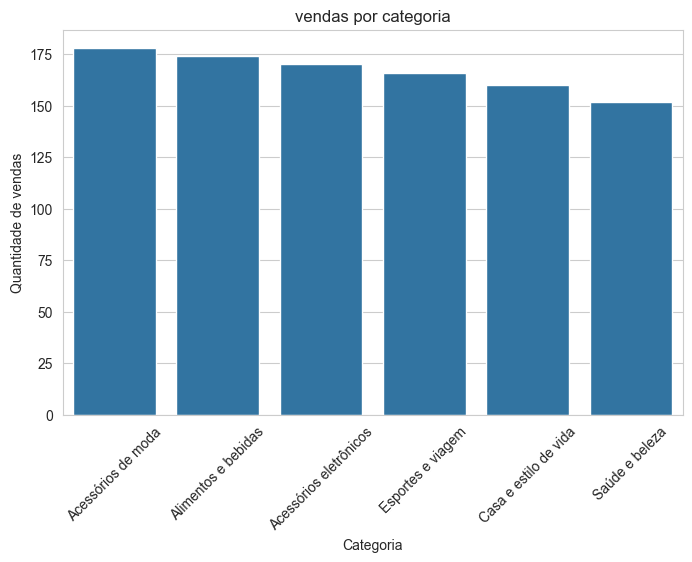

In [8]:
print("Qual  categoria gera mais receita ? ")

display(tabela.groupby("categoria")["vendas"].sum().sort_values(ascending = False))
receita_categoria = tabela.groupby("categoria")["vendas"].sum().sort_values(ascending = False)

# Criação do Gráfico : 

sns.set_style("whitegrid")

plt.figure(figsize= (8,5))

sns.barplot(
    x = receita_categoria.index , 
    y = receita_categoria.values,
    color = "orange" , 
)

plt.title("Receita total por categoria ")
plt.xlabel("Categoria")
plt.ylabel("Receita (R$)")
plt.xticks(rotation = 45)
plt.show()

print( "Qual categoria tem mais vendas ? ")
display(tabela["categoria"].value_counts())

vendas_categoria = tabela["categoria"].value_counts()

sns.set_style("whitegrid")

plt.figure(figsize= (8 , 5))

sns.barplot(
    x = vendas_categoria.index , 
    y = vendas_categoria.values , 
)
plt.title("vendas por categoria")
plt.xlabel("Categoria")
plt.ylabel("Quantidade de vendas")
plt.xticks(rotation = 45)
plt.show()




 Qual mês gerou mais vendas ? 


mes
Janeiro      352
Março        345
Fevereiro    303
Name: vendas, dtype: int64

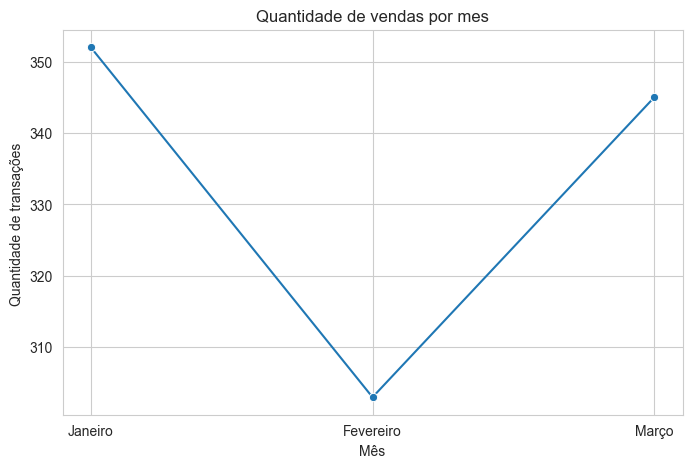

In [9]:

# Vendas por mês : 
print(f"{negrito}{azul} Qual mês gerou mais vendas ? {reset}")

display(tabela.groupby("mes")["vendas"].count().sort_values(ascending = False))

vendas_por_mes = tabela.groupby("mes")["vendas"].count().sort_values(ascending = False)

ordem = ["Janeiro" , "Fevereiro" , "Março"]
vendas_por_mes = vendas_por_mes.reindex(ordem)

plt.figure(figsize = (8,5))

sns.lineplot(
    x = vendas_por_mes.index , 
    y = vendas_por_mes.values , 
    errorbar = None , 
    marker = "o" , 
)
plt.title("Quantidade de vendas por mes")
plt.xlabel( "Mês")
plt.ylabel("Quantidade de transações ")
plt.show()

 Qual mês gerou mais receita ?  


mes
Janeiro     116,291.87
Março       109,455.51
Fevereiro    97,219.37
Name: vendas, dtype: float64

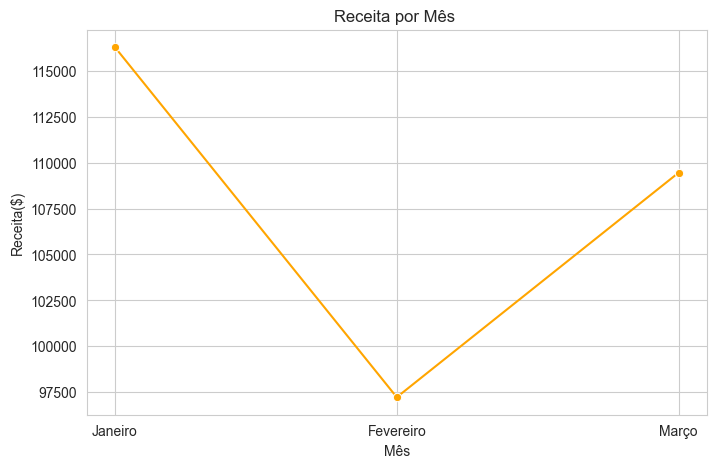

In [10]:
print(f"{negrito}{azul} Qual mês gerou mais receita ? {reset} ")
display(tabela.groupby("mes")["vendas"].sum().sort_values(ascending = False))
receita_por_mes = tabela.groupby("mes")["vendas"].sum().sort_values(ascending = False)

receita_por_mes = receita_por_mes.reindex(ordem)

plt.figure(figsize = (8,5))

sns.lineplot(

    x = receita_por_mes.index , 
    y = receita_por_mes.values , 
    errorbar = None , 
    marker = "o" , 
    color = "orange"
)
plt.title("Receita por Mês ")
plt.xlabel("Mês")
plt.ylabel("Receita($)")
plt.show()

In [11]:
#Gasto médio por gênero : 

print(f"{negrito}{azul} Gasto médio por gênero{reset}")

display(tabela.groupby("genero")["vendas"].mean().sort_values(ascending= False))

 Gasto médio por gênero


genero
Feminino    340.93
Masculino   299.06
Name: vendas, dtype: float64

 Qual dia da semana teve mais vendas ? 


dia_semana
Sábado           164
Terça-feira      158
Quarta-feira     143
Sexta-feira      139
Quinta-feira     138
Domingo          133
Segunda-feira    125
Name: vendas, dtype: int64

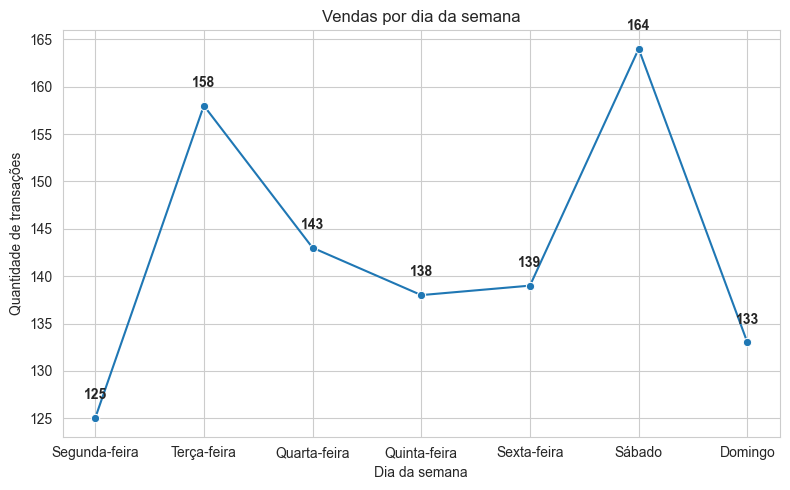

Qual dia da semana gera mais Receita ?  


dia_semana
Sábado          56,120.81
Terça-feira     51,482.25
Quinta-feira    45,349.25
Domingo         44,457.89
Sexta-feira     43,926.34
Quarta-feira    43,731.14
Segunda-feira   37,899.08
Name: vendas, dtype: float64

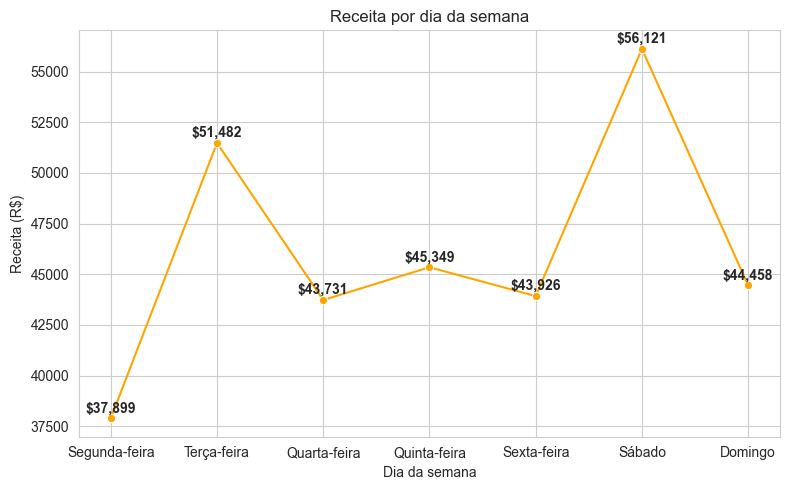

Ticket médio


dia_semana
Sábado          342.20
Domingo         334.27
Quinta-feira    328.62
Terça-feira     325.84
Sexta-feira     316.02
Quarta-feira    305.81
Segunda-feira   303.19
Name: vendas, dtype: float64

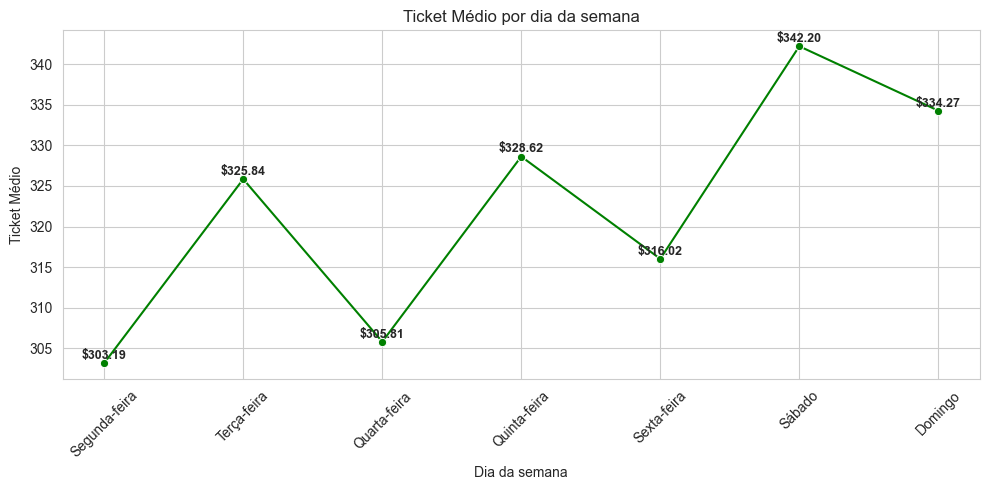

In [12]:
# Qual dia da semana teve mais vendas ? : 


print(f"{azul} Qual dia da semana teve mais vendas ? {reset}")

display(tabela.groupby("dia_semana")["vendas"].count().sort_values(ascending = False))

vendas_dia_semana = tabela.groupby("dia_semana")["vendas"].count().sort_values(ascending = False)

ordem_dias = ["Segunda-feira" , "Terça-feira" , "Quarta-feira" , "Quinta-feira" , "Sexta-feira", "Sábado" , "Domingo"]

vendas_dia_semana = vendas_dia_semana.reindex(ordem_dias)

plt.figure(figsize=(8,5))

sns.lineplot(
    x = vendas_dia_semana.index , 
    y = vendas_dia_semana.values ,
    marker = "o" , 
    errorbar = None , 
)
# Adicionando os valores em cima de cada ponto : 
for x, y in zip(vendas_dia_semana.index, vendas_dia_semana.values):
    plt.text(x, y + 2, f'{y}', ha='center', fontsize=10, fontweight = "bold")


plt.title('Vendas por dia da semana')
plt.xlabel('Dia da semana')
plt.ylabel('Quantidade de transações')

plt.tight_layout()
plt.show()


#Receita por dia da semana : 

print(f"{azul}Qual dia da semana gera mais Receita ?{negrito}  " ) 

display(tabela.groupby("dia_semana")["vendas"].sum().sort_values(ascending = False))

receita_por_dia_semana = tabela.groupby("dia_semana")["vendas"].sum().sort_values(ascending = False)

receita_por_dia_semana = receita_por_dia_semana.reindex(ordem_dias)

plt.figure(figsize = (8,5))


sns.lineplot(
    x= receita_por_dia_semana.index, 
    y=receita_por_dia_semana.values, 
    marker='o', 
    errorbar=None , 
    color = "orange" , 

)
# Adicionando os valores em cima de cada ponto
for x, y in zip(receita_por_dia_semana.index, receita_por_dia_semana.values):
    plt.text(x, y + 300, f'${y:,.0f}', ha='center', fontsize=10, fontweight = "bold")



plt.title('Receita por dia da semana')
plt.xlabel('Dia da semana')
plt.ylabel('Receita (R$)')
plt.tight_layout()
plt.show()




# Ticket Médio por dia da semana:

print(f"{azul}Ticket médio{reset}")
      
display(tabela.groupby("dia_semana")["vendas"].mean().sort_values(ascending = False))


ticket_medio_dia_semana = tabela.groupby("dia_semana")["vendas"].mean().round(2).reindex(ordem_dias).reset_index().sort_values(by = 'vendas' , ascending = False)

ticket_medio_dia_semana = ticket_medio_dia_semana.reindex(ordem_dias)

plt.close('all')

ordem_dias = ['Segunda-feira', 'Terça-feira', 'Quarta-feira', 'Quinta-feira', 'Sexta-feira', 'Sábado', 'Domingo']

ticket_medio = tabela.groupby('dia_semana')['vendas'].mean().round(2).reindex(ordem_dias).reset_index()
ticket_medio.columns = ['dia', 'ticket']

fig, ax = plt.subplots(figsize=(10,5))
sns.lineplot(data=ticket_medio, x='dia', y='ticket', marker='o', errorbar=None, color='green', ax=ax)

# posicionando o texto pelo indice numerico
for i in range(len(ticket_medio)):
    ax.text(i, ticket_medio['ticket'].iloc[i] + 0.5, 
            f"${ticket_medio['ticket'].iloc[i]:,.2f}",
            ha='center', fontsize=9, fontweight='bold')

plt.title('Ticket Médio por dia da semana')
plt.xlabel('Dia da semana')
plt.ylabel('Ticket Médio')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()





 Top 3 categorias por filial


categoria
Casa e estilo de vida    22,417.20
Esportes e viagem        19,372.70
Acessórios eletrônicos   18,317.11
Name: vendas, dtype: float64

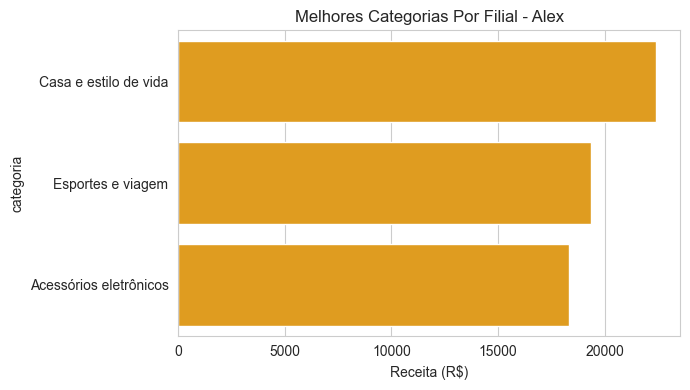

categoria
Esportes e viagem       19,988.20
Saúde e beleza          19,980.66
Casa e estilo de vida   17,549.16
Name: vendas, dtype: float64

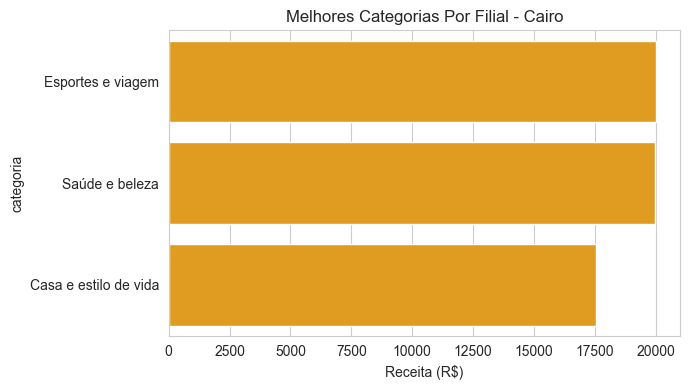

categoria
Alimentos e bebidas      23,766.85
Acessórios de moda       21,560.07
Acessórios eletrônicos   18,968.97
Name: vendas, dtype: float64

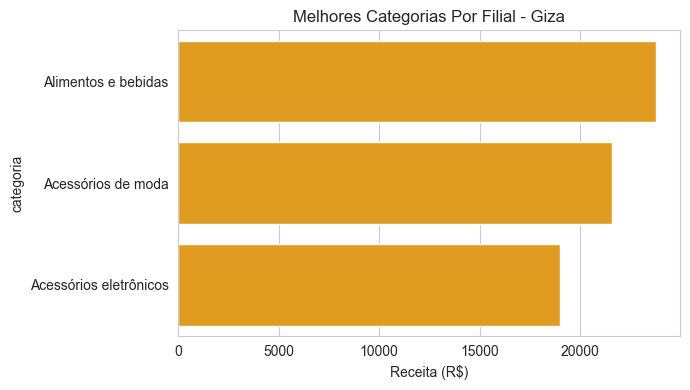

In [13]:
# Top 3 categorias por filial : 
print(f"{azul}{negrito} Top 3 categorias por filial{reset}")
for filial in ['Alex', 'Cairo', 'Giza']:
    display(tabela[tabela['filial'] == filial].groupby('categoria')['vendas'].sum().nlargest(3).sort_values(ascending= False))

    dados = tabela[tabela['filial'] == filial].groupby('categoria')['vendas'].sum().nlargest(3).sort_values(ascending= False)

    plt.figure(figsize=(7,4))

    sns.barplot(
        x=dados.values,         
        y=dados.index,
        color = "orange"
    )
    
    plt.title(f'Melhores Categorias Por Filial - {filial}')
    plt.xlabel('Receita (R$)')
    plt.tight_layout()

    plt.show()


In [14]:
#Categoria por filial geral : 

print(f"{azul}{negrito} Categoria por filial geral{reset}")
display(tabela.groupby(['filial', 'categoria'])['vendas']
        .sum()
        .groupby(level='filial')
        .nlargest(1)
        .reset_index(level=0, drop=True)
        .sort_values(ascending = False))


 Categoria por filial geral


filial  categoria            
Giza    Alimentos e bebidas     23,766.85
Alex    Casa e estilo de vida   22,417.20
Cairo   Esportes e viagem       19,988.20
Name: vendas, dtype: float64

 Pagamento preferido por tipo de cliente


,pagamento,tipo_cliente,vendas
0,Dinheiro,Member,192
1,Cartão de crédito,Member,187
2,Pix,Member,186
3,Pix,Normal,159
4,Dinheiro,Normal,152
5,Cartão de crédito,Normal,124


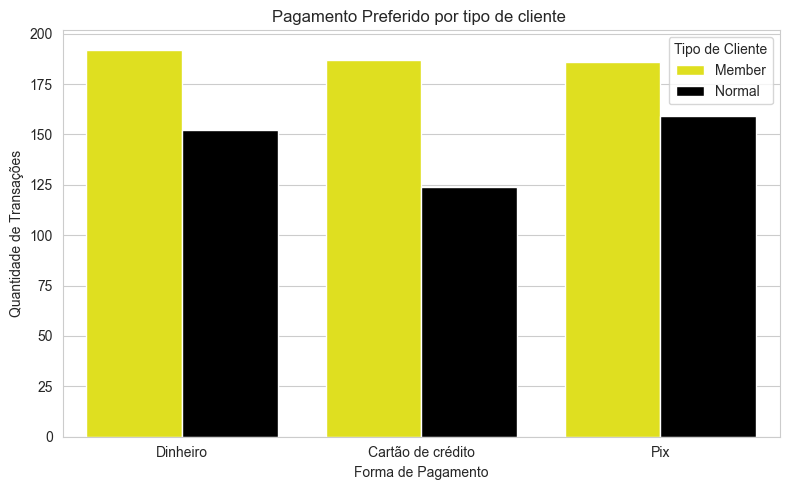

In [15]:
# Pagamento preferido por tipo de cliente : 
print(f"{negrito}{azul} Pagamento preferido por tipo de cliente")

display(tabela.groupby(["pagamento", "tipo_cliente"])["vendas"].count().sort_values(ascending = False).reset_index())
pagamento_cliente = tabela.groupby(["pagamento", "tipo_cliente"])["vendas"].count().sort_values(ascending = False).reset_index()

pagamento_cliente.columns = ["pagamento" , "tipo_cliente" , "vendas"]

plt.figure(figsize = (8,5))

sns.barplot(
    data = pagamento_cliente, 
    x = "pagamento",
    y = "vendas" , 
    hue = "tipo_cliente"  ,    
    palette = ({"Member" : "yellow", "Normal": "black"})      
)

plt.title("Pagamento Preferido por tipo de cliente ")
plt.xlabel("Forma de Pagamento")
plt.ylabel("Quantidade de Transações")
plt.legend(title = "Tipo de Cliente")
plt.tight_layout()
plt.show()






In [16]:
# Perguntas de Negócio :
# 1 Hipótese: 
print(f"{azul}porque a categoria de Saúde e beleza gera menos receita e menas vendas ? analisando com os dados que temos :{reset}\n")
print("vamos verificar as avaliações :") 

display(tabela.groupby("categoria")["avaliacao"].mean().sort_values(ascending=False))
print(f"{vermelho} hipótese eliminada - avaliações praticamente iguais {reset}  \n")

# 2 Hipótese : 
print("Verificando se o preço de Saúde e Beleza e alto comparado as outras :")

display(tabela.groupby("categoria")["preco_unitario"].mean().sort_values(ascending =False))
print(f"{vermelho} hipótese eliminada - preço normal{reset}")

saude = tabela[tabela["categoria"] == "Saúde e beleza"]
print(f"{azul}O problema esta concentrado em alguma filial ? ")

display(saude.groupby("filial")["vendas"].sum().sort_values(ascending = False))
print(f"{verde} hipótese certa - Filial Alex{reset}\n")

tabela["genero"].head()

# 3 Hipótese : 

print(f"{azul} Algum genero compra menos essa categoria ?{reset}")

display(saude.groupby("genero")["quantidade"].sum().sort_values(ascending= False))
print(f"{vermelho} hipótese eliminada{reset}\n")


# 4 Hipótese :
print(f"{azul}Qual horário essa categoria vende menos ? {reset}") 

resultado_saude = saude.groupby("hora")["vendas"].sum().sort_values(ascending = False).head(3)

resultado_saude.index = resultado_saude.index.astype(str) + "h"

display(resultado_saude)
print(f"{verde} hipótese certa - 19h horário de pico, Porém a categoria vende menos ")


porque a categoria de Saúde e beleza gera menos receita e menas vendas ? analisando com os dados que temos :

vamos verificar as avaliações :


categoria
Alimentos e bebidas      7.11
Acessórios de moda       7.03
Saúde e beleza           7.00
Acessórios eletrônicos   6.92
Esportes e viagem        6.92
Casa e estilo de vida    6.84
Name: avaliacao, dtype: float64

 hipótese eliminada - avaliações praticamente iguais   

Verificando se o preço de Saúde e Beleza e alto comparado as outras :


categoria
Acessórios de moda       57.15
Esportes e viagem        56.99
Alimentos e bebidas      56.01
Casa e estilo de vida    55.32
Saúde e beleza           54.85
Acessórios eletrônicos   53.55
Name: preco_unitario, dtype: float64

 hipótese eliminada - preço normal
O problema esta concentrado em alguma filial ? 


...

 hipótese certa - Filial Alex

 Algum genero compra menos essa categoria ?


genero
Masculino    429
Feminino     425
Name: quantidade, dtype: int64

 hipótese eliminada

Qual horário essa categoria vende menos ? 


hora
14h   7,431.80
13h   5,868.67
19h   5,365.42
Name: vendas, dtype: float64

 hipótese certa - 19h horário de pico, Porém a categoria vende menos 


## Análise — Por que a Categoria De Saúde e Beleza gera menos resultados ?

### Hipóteses testadas

| Hipótese | Resultado |
|----------|-----------|
| Avaliação baixa dos clientes | <span style="color:red"> Eliminada</span> |
| Preço alto comparado às outras | <span style="color:red"> Eliminada</span> |
| Problema concentrado na Filial Alex | <span style="color:green"> Confirmada</span> |
| Baixa venda no horário de pico 19h | <span style="color:green"> Confirmada</span> |

### <span style ="color:#1D9E75">Conclusão</span>
O problema está concentrado na **Filial Alex** e no **horário de pico (19h)**.  
Preço e avaliação foram descartados como causas com base nos dados.

### <span style="color:#1D9E75">Recomendações</span>
1. Reposicionar os produtos de Saúde e beleza em local mais visível na Filial Alex.

2. Criar promoção específica dessa categoria no horário das 19h em Alex.

3. Monitorar os resultados por 30 dias e comparar com Cairo.


# 📋 Conclusões Finais

## <span style="color:#1D9E75">Filiais</span>
| Métrica | Líder |
|---------|-------|
| Mais transações | <span style="color:#1D9E75">**Alex** (340)</span> |
| Mais receita | <span style="color:#1D9E75">**Giza** ($110.568)</span> |
| Maior ticket médio | <span style="color:#1D9E75">**Giza** ($337)</span> |
| Categoria líder — Alex | <span style="color:#1D9E75">**Casa e estilo de vida**</span> |
| Categoria líder — Cairo | <span style="color:#1D9E75">**Esportes e viagem**</span> |
| Categoria líder — Giza | <span style="color:#1D9E75">**Alimentos e bebidas**</span> |

> Giza atrai menos clientes mas cada um gasta mais. Alex atrai mais clientes mas com ticket médio menor. Cada filial tem um perfil de consumo diferente.

### Top 3 categorias por filial
| Filial | 1º | 2º | 3º |
|--------|----|----|-----|
| Alex | Casa e estilo de vida | Esportes e viagem | Acessórios eletrônicos |
| Cairo | Esportes e viagem | Saúde e beleza | Casa e estilo de vida |
| Giza | Alimentos e bebidas | Acessórios de moda | Acessórios eletrônicos |

> Cada filial tem um perfil de consumo diferente — nenhuma categoria lidera nas três ao mesmo tempo.

## <span style="color:#1D9E75">Categorias</span>
| Métrica | Líder |
|---------|-------|
| Mais transações | <span style="color:#1D9E75">**Acessórios de moda** (178)</span> |
| Mais receita | <span style="color:#1D9E75">**Alimentos e bebidas** ($56.144)</span> |
| Menor receita | <span style="color:red">**Saúde e beleza** ($49.193) ⚠️</span> |

## <span style="color:#1D9E75">Pagamento</span>
| Métrica | Líder |
|---------|-------|
| Mais usado | <span style="color:#1D9E75">**Pix** (345 transações)</span> |
| Mais receita | <span style="color:#1D9E75">**Cash** ($112.206)</span> |


## <span style="color:#1D9E75">Clientes</span>
| Métrica | Resultado |
|---------|-----------|
| Maior ticket médio | <span style="color:#1D9E75">**Member** ($335 vs $306)</span> |
| Maior gasto por compra | <span style="color:#1D9E75">**Feminino** ($340 vs $299)</span> |
| Pagamento preferido — Member | <span style="color:#1D9E75">**Equilibrado** — Cash (192), Credit card (187), Pix (186)</span> | 
| Pagamento preferido — Normal | <span style="color:#1D9E75">**Pix** (159), **Cash** (152) — evitam Credit card (124)</span> |

## <span style="color:#1D9E75">Tempo</span>
| Métrica | Resultado |
|---------|-----------|
| Melhor mês | <span style="color:#1D9E75">**Janeiro** ($116.291)</span> |
| Pior mês | <span style="color:red">**Fevereiro** ($97.219) ⚠️</span> |
| Melhor dia | <span style="color:#1D9E75">**Sábado**</span> |
| Horário de pico | <span style="color:#1D9E75">**19h** ($39.699)</span> |

## <span style="color:#1D9E75">Distribuição das Vendas</span>
| Métrica | Resultado |
|---------|-----------|
| Faixa mais comum | <span style="color:#1D9E75">**$50 a $300**</span> |
| Compras acima de $600 | <span style="color:red">**Raras** — menos de 10% das transações</span> |
| Perfil do cliente | Compras de pequeno a médio porte — compra do dia a dia |